# Exploratory Data Analysis


In [1]:
import pandas as pd

df_final = pd.read_csv("../data/df_final.csv")

df_final.head()

,REF_AREA,TIME_PERIOD,ACCIDENTS,INJURED,KILLED,REGION_CODE,PROVINCE_CODE,MUNICIPALITY,PROVINCE,AREA_KM2,POPULATION,YEAR,ACCIDENTS_PER_CAPITA,ACCIDENTS_PER_KM2
0,1001,2020,4.0,4.0,0.0,1.0,201.0,Agliè,TO,13.1462,2545.0,2020.0,0.001572,0.304270
1,1001,2021,2.0,2.0,0.0,1.0,201.0,Agliè,TO,13.1463,2562.0,2021.0,0.000781,0.152134
2,1001,2022,3.0,5.0,0.0,1.0,201.0,Agliè,TO,13.1463,2568.0,2022.0,0.001168,0.228201
3,1001,2023,3.0,6.0,1.0,1.0,201.0,Agliè,TO,13.1463,2596.0,2023.0,0.001156,0.228201
4,1001,2024,2.0,5.0,0.0,1.0,201.0,Agliè,TO,13.1463,2585.0,2024.0,0.000774,0.152134


We start by trying to explore how did road accidents, injuries, and fatalities change in Italy in the years we consider.

In [3]:
yearly_summary = df_final.groupby("TIME_PERIOD")[
  ["ACCIDENTS", "INJURED", "KILLED"]
].sum()

print(yearly_summary)

             ACCIDENTS   INJURED  KILLED
TIME_PERIOD                             
2020          118298.0  159248.0  2395.0
2021          151875.0  204728.0  2875.0
2022          165889.0  223475.0  3159.0
2023          166525.0  224634.0  3039.0
2024          173364.0  233853.0  3030.0


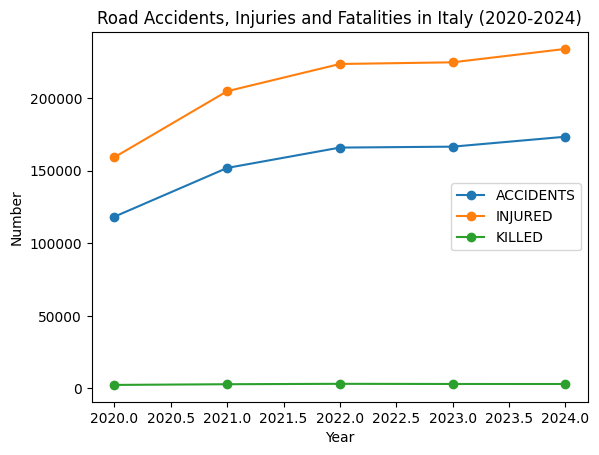

In [4]:
# quick time series graph
import matplotlib.pyplot as plt

yearly_summary.plot(
  kind="line",
  marker="o"
)

plt.title("Road Accidents, Injuries and Fatalities in Italy (2020-2024)")
plt.xlabel("Year")
plt.ylabel("Number")
plt.show()

             ACCIDENTS    INJURED     KILLED
TIME_PERIOD                                 
2020               NaN        NaN        NaN
2021         28.383405  28.559228  20.041754
2022          9.227325   9.157028   9.878261
2023          0.383389   0.518626  -3.798670
2024          4.106891   4.104009  -0.296150


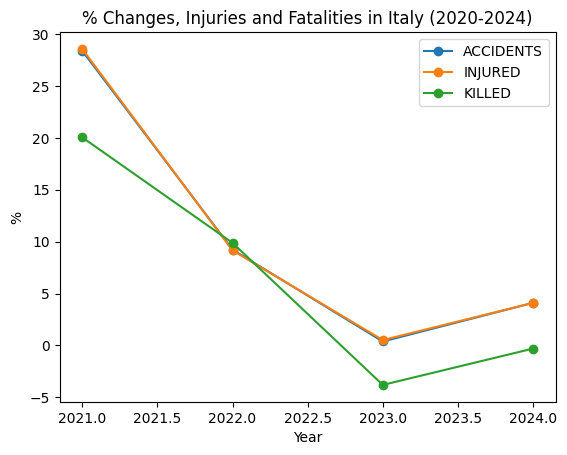

In [ ]:
# To see the trends we calculate percentage changes, which we can get with pct_change() function
yearly_change = yearly_summary.pct_change() * 100

print(yearly_change)

# The below graph changes the scale issue and shows clearly the drop 2020 --> 2021 in accidents and injuries. 2020 was likely an unusually low year of accidents due to COVID.
yearly_change.plot(
  kind="line",
  marker="o"
)

plt.title("Annual % Change in Road Accidents, Injuries and Fatalities (2020-2024)")
plt.xlabel("Year")
plt.ylabel("%")
plt.show()


Next I want to see where the accidents are actually concentrated. First we aggregate across years for each municipality and rank the ones where most accidents occur in the 5 year span. Below I see the top 10.

In [9]:
municipality_summary = df_final.groupby("MUNICIPALITY")[
  ["ACCIDENTS", "INJURED", "KILLED"]
].sum()

municipality_summary = municipality_summary.sort_values("ACCIDENTS", ascending=False)

print(municipality_summary.head(10))

              ACCIDENTS  INJURED  KILLED
MUNICIPALITY                            
Roma            59280.0  74151.0   663.0
Milano          35659.0  44480.0   191.0
Genova          17875.0  21161.0    80.0
Torino          13702.0  19469.0    99.0
Napoli          11219.0  14417.0   157.0
Firenze         11019.0  12907.0    61.0
Bologna          9461.0  11934.0    81.0
Palermo          8633.0  11205.0   106.0
Bari             7384.0  10611.0    58.0
Catania          6333.0   8714.0    73.0


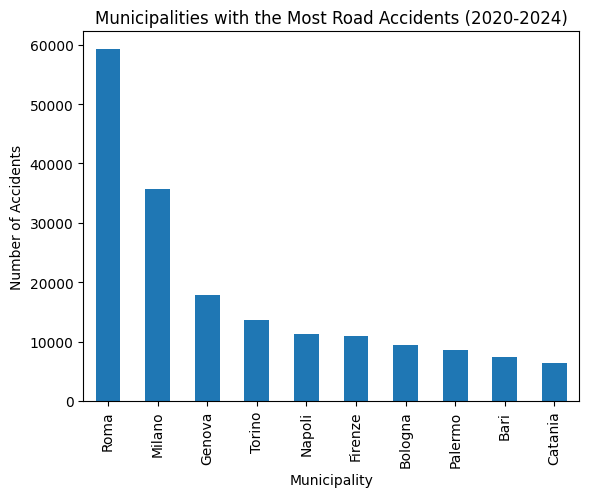

In [10]:
# Plot the top 10 municipalities in terms of absolute number of accidents
top10 = municipality_summary.head(10)

top10["ACCIDENTS"].plot(kind="bar")

plt.title("Municipalities with the Most Road Accidents (2020-2024)")
plt.xlabel("Municipality")
plt.ylabel("Number of Accidents")
plt.show()

Obviously, larger cities have more accidents, with Rome by far dominating. However, absolute numbers are strongly influenced by population size. We therefore compare municipalities using the accidents-per-capita indicator created previously, taking its average over the 2020–2024 period.

In [12]:
# Average annual accidents per capita by municipality
municipality_per_capita = (
    df_final.groupby("MUNICIPALITY")["ACCIDENTS_PER_CAPITA"]
    .mean()
    .sort_values(ascending=False)
)

print(municipality_per_capita.head(10))

MUNICIPALITY
Moncenisio                 0.032476
Argentera                  0.015420
Rocca Pia                  0.014886
Brienno                    0.014817
Cerignale                  0.014713
Pietraporzio               0.014149
Ponte Gardena/Waidbruck    0.013308
Carrodano                  0.013191
Dorio                      0.013161
Forte dei Marmi            0.013070
Name: ACCIDENTS_PER_CAPITA, dtype: float64


The hihest per-capita accident rates are concentrated among small municipalities. These results should be interpreted cautiously, as per-capita indicators become highly sensitive to individual accidents when population sizes are very small.
We now move on to do a similar exercise with the other indicator we created prior, accidents per km2.

In [13]:
# Average annual accidents per km² by municipality
municipality_per_km2 = (
    df_final.groupby("MUNICIPALITY")["ACCIDENTS_PER_KM2"]
    .mean()
    .sort_values(ascending=False)
)

print(municipality_per_km2.head(10))

MUNICIPALITY
Milano                39.224016
Cinisello Balsamo     21.879888
Firenze               21.540675
Torino                21.072855
Bergamo               20.790761
Corsico               20.621606
Cormano               19.314542
Napoli                18.824700
Sesto San Giovanni    17.403314
Portici               16.027670
Name: ACCIDENTS_PER_KM2, dtype: float64


So overall we have that:

- Absolute accident rankings are dominated by large cities, with Rome leading.
- Accidents per capita rankings are dominated by small municipalities, with Moncenisio leading.
- Accidents per km2 are dominated by dense urban areas, with Milano leading.

Before moving on we show this graphically.

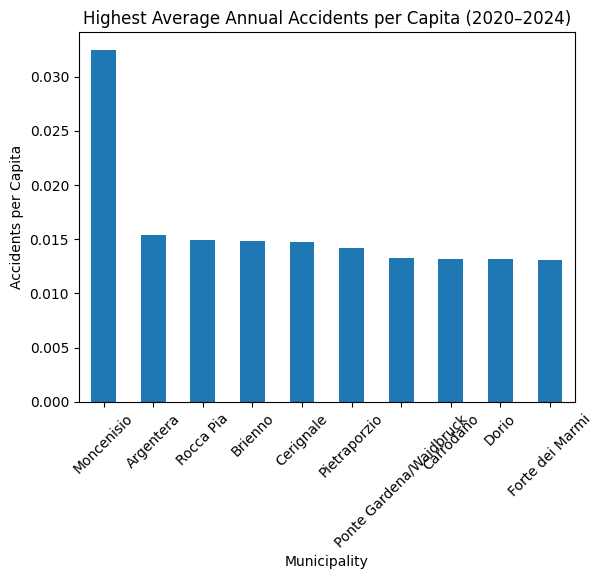

In [ ]:
municipality_per_capita.head(10).plot(kind="bar")
plt.title("Highest Average Annual Accidents per Capita (2020–2024)")
plt.xlabel("Municipality")
plt.ylabel("Accidents per Capita")
plt.xticks(rotation=45)
plt.show()

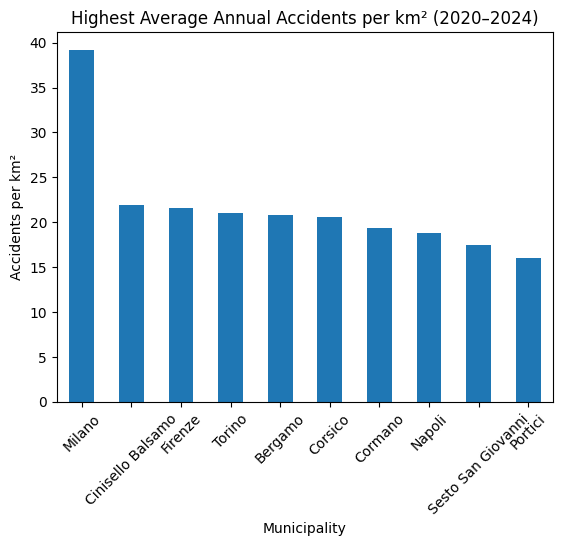

In [ ]:
municipality_per_km2.head(10).plot(kind="bar")
plt.title("Highest Average Annual Accidents per km² (2020–2024)")
plt.xlabel("Municipality")
plt.ylabel("Accidents per km²")
plt.xticks(rotation=45)
plt.show()

Next I am interested in exploring how the normalized indicators (per capita and per km2) evolve nationally over time. We already know accidents raise in time, but we want to know if this reflects a population increase or if the accident rate itself has increased.

We need to calculate the national rate correctly from the totals.

TIME_PERIOD
2020    0.001997
2021    0.002573
2022    0.002812
2023    0.002824
2024    0.003007
dtype: float64


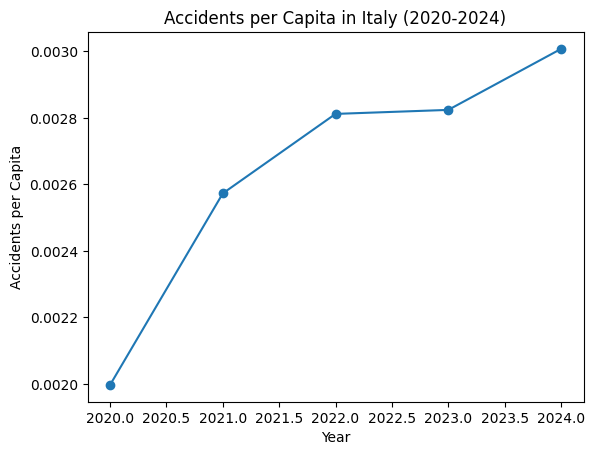

In [17]:
# National accidents per capita by year
national_per_capita = (
  df_final.groupby("TIME_PERIOD")["ACCIDENTS"].sum() /
  df_final.groupby("TIME_PERIOD")["POPULATION"].sum()
)

print(national_per_capita)

national_per_capita.plot(kind="line", marker="o")

plt.title("Accidents per Capita in Italy (2020-2024)")
plt.xlabel("Year")
plt.ylabel("Accidents per Capita")
plt.show()

The national accident rate increased from approximately 0.0020 accidents per capita in 2020 to 0.0030 in 2024. This suggests that the increase in the absolute number of accidents is not explained by population growth alone. The strongest increase occurred between 2020 and 2021, while the rate remained relatively stable between 2022 and 2023 before increasing again in 2024.

We repeat for km2

In [18]:
df_final.head()

,REF_AREA,TIME_PERIOD,ACCIDENTS,INJURED,KILLED,REGION_CODE,PROVINCE_CODE,MUNICIPALITY,PROVINCE,AREA_KM2,POPULATION,YEAR,ACCIDENTS_PER_CAPITA,ACCIDENTS_PER_KM2
0,1001,2020,4.0,4.0,0.0,1.0,201.0,Agliè,TO,13.1462,2545.0,2020.0,0.001572,0.304270
1,1001,2021,2.0,2.0,0.0,1.0,201.0,Agliè,TO,13.1463,2562.0,2021.0,0.000781,0.152134
2,1001,2022,3.0,5.0,0.0,1.0,201.0,Agliè,TO,13.1463,2568.0,2022.0,0.001168,0.228201
3,1001,2023,3.0,6.0,1.0,1.0,201.0,Agliè,TO,13.1463,2596.0,2023.0,0.001156,0.228201
4,1001,2024,2.0,5.0,0.0,1.0,201.0,Agliè,TO,13.1463,2585.0,2024.0,0.000774,0.152134


TIME_PERIOD
2020    0.391627
2021    0.502715
2022    0.549102
2023    0.551207
2024    0.655763
dtype: float64


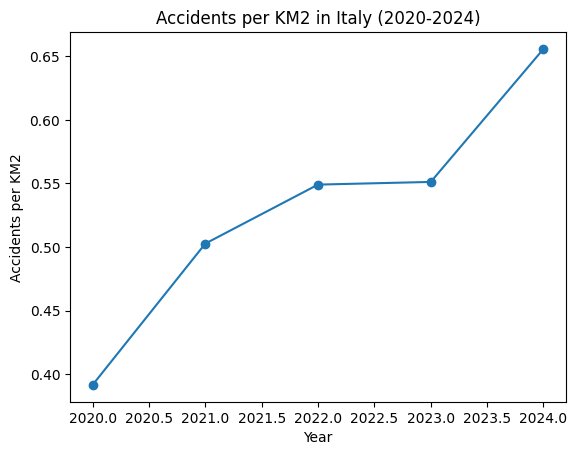

In [ ]:
# National accidents per km2 by year
national_per_km2 = (
  df_final.groupby("TIME_PERIOD")["ACCIDENTS"].sum() /
  df_final.groupby("TIME_PERIOD")["AREA_KM2"].sum()
)

print(national_per_km2)

national_per_km2.plot(kind="line", marker="o")

plt.title("Accidents per KM2 in Italy (2020-2024)")
plt.xlabel("Year")
plt.ylabel("Accidents per KM2")
plt.show()

## Correlations

I am interested now in exploring the correlations between accidents and outcomes

In [20]:
correlation = df_final[
  ["ACCIDENTS", "INJURED", "KILLED"]
].corr()

print(correlation)

           ACCIDENTS   INJURED    KILLED
ACCIDENTS   1.000000  0.998997  0.887227
INJURED     0.998997  1.000000  0.890924
KILLED      0.887227  0.890924  1.000000


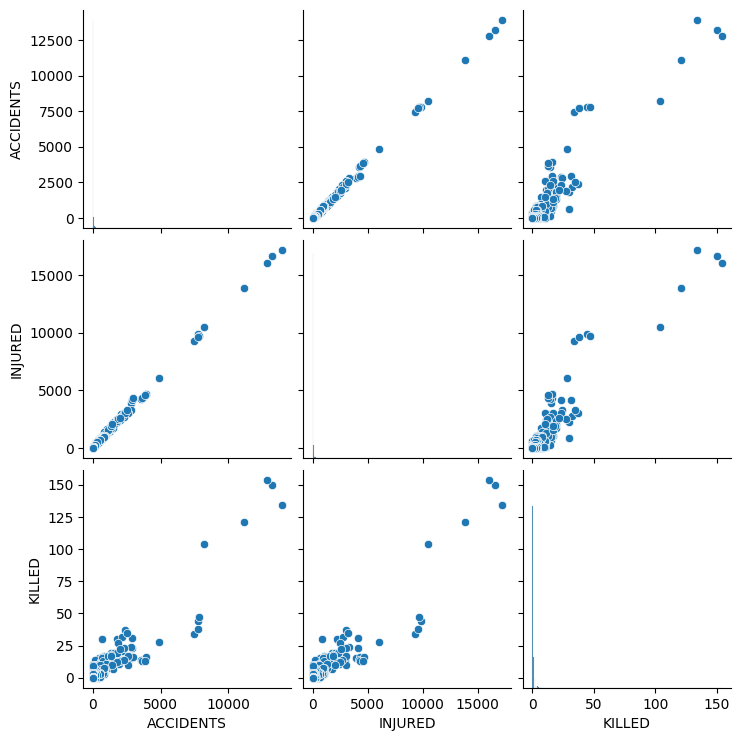

In [21]:
# We do a pairplot to visualise better the relationships
import seaborn as sns

sns.pairplot(
    df_final[["ACCIDENTS", "INJURED", "KILLED"]]
)

plt.show()


The main things we can see from the above pair plots are:

- Accidents and injuries have an extremely strong positive relationship - municipalities with the most accidents record also more injured people.
- Faralities are positively correlated with accidents but much less tightly - for a given number of accidents there is more variation in deaths.
- All variables are right-skewed - most municipality-year observations are close to 0 while a small number of large municipalities generate very large results.
- The above is consistent with prior descriptive results - large cities dominate in absolute counts so these are meaningful extreme observations.

To see how the relationships between variables change geographically we focus on provinces.

We first calculate the mean accidents per capita and per km2 in each province and see which provinces lead

PROVINCE
TS    0.003420
FI    0.003315
SV    0.003310
RA    0.003279
LI    0.003212
PC    0.002848
GO    0.002824
FC    0.002616
PT    0.002587
BO    0.002542
Name: ACCIDENTS_PER_CAPITA, dtype: float64


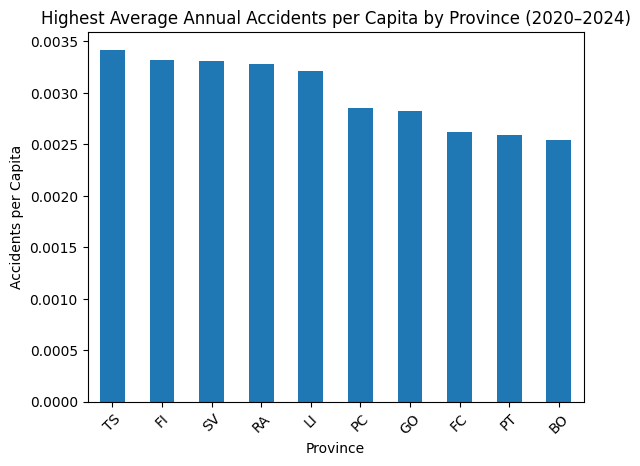

In [25]:
# Average annual accidents per capita by province
province_per_capita = (
    df_final.groupby("PROVINCE")["ACCIDENTS_PER_CAPITA"]
    .mean()
    .sort_values(ascending=False)
)

print(province_per_capita.head(10))

province_per_capita.head(10).plot(kind="bar")

plt.title("Highest Average Annual Accidents per Capita by Province (2020–2024)")
plt.xlabel("Province")
plt.ylabel("Accidents per Capita")
plt.xticks(rotation=45)
plt.show()

PROVINCE
MB    4.038050
MI    3.743150
PO    2.086334
TS    2.041514
RN    1.785527
CT    1.669163
FI    1.533664
VA    1.309550
PT    1.294089
LC    1.210788
Name: ACCIDENTS_PER_KM2, dtype: float64


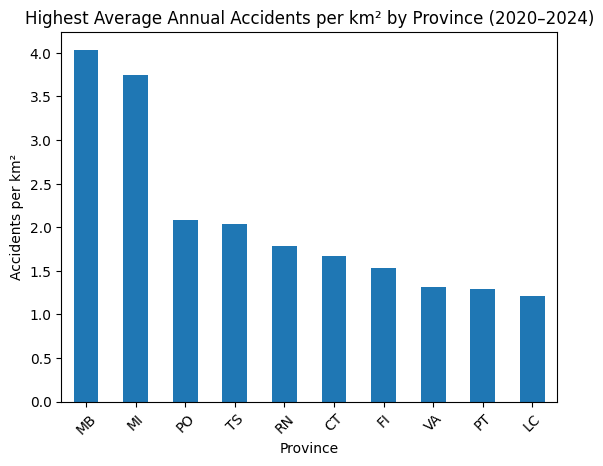

In [26]:
# Average annual accidents per km² by province
province_per_km2 = (
    df_final.groupby("PROVINCE")["ACCIDENTS_PER_KM2"]
    .mean()
    .sort_values(ascending=False)
)

print(province_per_km2.head(10))

province_per_km2.head(10).plot(kind="bar")

plt.title("Highest Average Annual Accidents per km² by Province (2020–2024)")
plt.xlabel("Province")
plt.ylabel("Accidents per km²")
plt.xticks(rotation=45)
plt.show()

For per capita, TS (Trieste), FI (Firenze), SV (Savona), RA (Ravenna), and LI (Livorno) come out highest. For per km², MB (Monza e Brianza) and MI (Milano) stand out, which makes intuitive sense because this measure emphasizes spatial concentration rather than population-normalized accident frequency.